# Camino del terreno — Fase 3: referencia y validación

- **Paso 11**: tabla `terreno/quebradas_referencia.csv`. Nombres de ANA y del catálogo; punto de salida = extremo de la línea de ANA más cercano al cauce principal; áreas solo de SIGRID.
- **Paso 12**: *recall* y *precision* de nuestra red (por umbral) contra ANA, con un buffer de 90 m.
  - *Recall* = % de la red de ANA que tiene un cauce nuestro a ≤ 90 m.
  - *Precision* = % de nuestra red que tiene un cauce de ANA a ≤ 90 m.
- **Paso 13**: cruce de cada quebrada de referencia con las cuencas candidatas (o delimitación desde su punto) y chequeos.

In [1]:
from pathlib import Path
import unicodedata, difflib, tempfile
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import shapely
from rasterio import features
from rasterio.warp import transform as warp_transform
from scipy import ndimage as ndi
from scipy.spatial import cKDTree
from shapely.geometry import Point, box, shape
from shapely.ops import linemerge, unary_union
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import whitebox

# --- Parámetros ---
UMBRAL_CAUCE = 500           # celdas; el mismo de la fase 1 (elegido en el paso 12; antes 1000)
UMBRALES = [500, 1000, 2500, 5000]
BUFFER_M = 90
SNAP_UMBRAL = 100            # celdas: cauces a los que se ajusta un punto de referencia
SNAP_MAX_M = 150
PASO_CONSULTA_M = 150        # la consulta empieza 150 m aguas arriba de la salida, sobre la línea de ANA...
MAX_CONSULTA_M = 1000        # ...y sube por la línea (cada 30 m) hasta 1 km buscando la primera cuenca candidata
CELDA_M2 = 900

TERRENO = Path.cwd().resolve()
RAIZ = TERRENO.parent
FUENTES = TERRENO / "fuentes"
DEM, FDIR, FACC = RAIZ / "fabdem_chosica_hydro.tif", RAIZ / "flow_direction_d8.tif", RAIZ / "flow_accumulation_d8.tif"

wbt = whitebox.WhiteboxTools()
wbt.set_verbose_mode(False)

0

In [2]:
with rasterio.open(DEM) as src:
    dem = src.read(1); perfil = src.profile; T = src.transform; CRS = src.crs
with rasterio.open(FDIR) as src:
    fdir = src.read(1)
with rasterio.open(FACC) as src:
    acc = src.read(1); valido = acc != src.nodata
with rasterio.open(TERRENO / "cauce_principal.tif") as src:
    rio = src.read(1)                     # 1 = Rímac, 2 = Santa Eulalia
with rasterio.open(TERRENO / "cuencas_candidatas.tif") as src:
    ws = src.read(1); ws = np.where((ws == src.nodata) | ~valido, 0, ws).astype(np.int32)
R, C = acc.shape
principal = rio > 0
borde = valido & ~ndi.binary_erosion(valido, structure=np.ones((3, 3)), border_value=0)
pp = pd.read_csv(TERRENO / "pour_points_candidatos.csv")
cand = gpd.read_file(TERRENO / "cuencas_candidatas.geojson").to_crs(CRS).set_index("cuenca_id")

# Red D8 (convención Whitebox)
D8 = {1: (-1, 1), 2: (0, 1), 4: (1, 1), 8: (1, 0), 16: (1, -1), 32: (0, -1), 64: (-1, -1), 128: (-1, 0)}
idx = np.arange(R * C).reshape(R, C)
abajo = np.full(R * C, -1)
for d, (dr, dc) in D8.items():
    rr, cc = np.where((fdir == d) & valido)
    r2, c2 = rr + dr, cc + dc
    ok = (r2 >= 0) & (r2 < R) & (c2 >= 0) & (c2 < C)
    ok[ok] &= valido[r2[ok], c2[ok]]
    abajo[idx[rr[ok], cc[ok]]] = idx[r2[ok], c2[ok]]
salida_final = np.where(abajo < 0, np.arange(R * C), abajo)
for _ in range(30):
    salida_final = salida_final[salida_final]
salida_final = salida_final.reshape(R, C)
paso_m = np.where(np.isin(fdir, [1, 4, 16, 64]), 30 * np.sqrt(2), 30.0)   # largo del paso D8 de cada celda

def trazar(r, c, mascara):
    camino = [(r, c)]
    while abajo[idx[r, c]] >= 0:
        r, c = divmod(int(abajo[idx[r, c]]), C)
        if not mascara[r, c]: break
        camino.append((r, c))
    return camino

def entrada(mascara):
    # Celda del río sin otra celda del mismo río aguas arriba
    celdas = idx[mascara]
    return divmod(int(np.setdiff1d(celdas, abajo[celdas])[0]), C)

traza = {"Rímac": trazar(*entrada(rio == 1), rio == 1), "Santa Eulalia": trazar(*entrada(rio == 2), rio == 2)}
salida_rimac = traza["Rímac"][-1]
zona_rimac = valido & (salida_final == salida_final[salida_rimac])     # todo lo que drena a la salida del Rímac

xy_rio = {k: np.array(rasterio.transform.xy(T, *zip(*v))).T for k, v in traza.items()}
arbol_rio = {k: cKDTree(v) for k, v in xy_rio.items()}

def ubicar(x, y):
    # Río más cercano, km desde la salida (Rímac) o desde la confluencia (Santa Eulalia), margen y distancia.
    mejor = min(((k, *arbol_rio[k].query([x, y])) for k in xy_rio), key=lambda t: t[1])
    k, dist, i = mejor; v = xy_rio[k]
    i0, i1 = max(i - 5, 0), min(i + 5, len(v) - 1)
    dx, dy = v[i1] - v[i0]                     # sentido aguas abajo
    px, py = x - v[i, 0], y - v[i, 1]
    margen = "izquierda" if dx * py - dy * px > 0 else "derecha"
    return k, round((len(v) - 1 - i) * 0.03, 2), margen, round(dist)

xs, ys = rasterio.transform.xy(T, *np.where(principal))
arbol_principal = cKDTree(np.c_[xs, ys])
X0, Y0, X1, Y1 = rasterio.transform.array_bounds(R, C, T)
zona_valida = unary_union([shape(g) for g, v in features.shapes(valido.astype(np.uint8), mask=valido, transform=T)])

def hillshade(z, az=315, alt=45):
    z = np.where(valido, z, np.nan)
    gy, gx = np.gradient(z, 30)
    pend = np.arctan(np.hypot(gx, gy)); asp = np.arctan2(-gx, gy)
    az, alt = np.radians(360 - az + 90), np.radians(alt)
    return np.ma.masked_invalid(np.sin(alt) * np.cos(pend) + np.cos(alt) * np.sin(pend) * np.cos(az - asp))
hs = hillshade(dem)
print("Rímac:", len(traza["Rímac"]), "celdas | Santa Eulalia:", len(traza["Santa Eulalia"]), "| cuencas candidatas:", len(cand))

Rímac: 1138 celdas | Santa Eulalia: 482 | cuencas candidatas: 89


## Paso 11 — Tabla de referencia
Para cada quebrada con nombre en ANA (capas Estudios y Carta IGN):
- **punto de salida**: el extremo de su línea (dentro del recorte) más cercano al cauce principal. Si la quebrada está en las dos capas, uso la capa cuyo extremo queda más cerca.
  - Excepción: si ese extremo no es el más bajo, la quebrada corre alejándose del Rímac (Lurín, Huaycoloro). Ahí uso el extremo más bajo, y la columna `regla_salida` lo indica;
- **puntos de consulta**: puntos sobre la misma línea, cada 30 m, desde 150 m hasta 1 km aguas arriba de la salida. Sirven para registrar dónde entra la línea en su cuenca (paso 13).

In [3]:
def normalizar(t):
    t = unicodedata.normalize("NFKD", str(t)).encode("ascii", "ignore").decode().lower().strip()
    for pre in ("quebrada ", "rio "):
        if t.startswith(pre): t = t[len(pre):]
    return t

def partes(g):
    return list(g.geoms) if hasattr(g, "geoms") else [g]

ana = {"ANA Estudios": gpd.read_file(FUENTES / "ana_rios_quebradas_estudios.geojson").to_crs(CRS),
       "ANA Carta IGN": gpd.read_file(FUENTES / "ana_rios_quebradas_carta_ign.geojson").to_crs(CRS)}

filas = []
for capa, g in ana.items():
    g = g[g["NOMBRE_COMPLETO"].fillna("").str.strip() != ""]
    for nombre, s in g.groupby(g["NOMBRE_COMPLETO"].str.strip()):
        u = unary_union(list(s.geometry))
        u = linemerge(u) if u.geom_type == "MultiLineString" else u
        u = u.intersection(zona_valida)
        lineas = [l for l in partes(u) if l.geom_type == "LineString" and l.length > 0]
        if not lineas: continue
        extremos = [(l, 0) for l in lineas] + [(l, 1) for l in lineas]
        pts = np.array([l.coords[0] if k == 0 else l.coords[-1] for l, k in extremos])
        dist = arbol_principal.query(pts)[0]
        er, ec = rasterio.transform.rowcol(T, pts[:, 0], pts[:, 1])
        z = dem[np.clip(er, 0, R - 1), np.clip(ec, 0, C - 1)]
        j = int(np.argmin(dist)); regla = "más cercano al cauce principal"
        otro = (j + len(lineas)) % (2 * len(lineas))      # el otro extremo del mismo tramo
        if z[j] > z[otro] + 10:          # el tramo sube hacia el Rímac: la quebrada corre alejándose; su salida real es el extremo más bajo
            j = int(np.argmin(z)); regla = "más bajo (no drena al Rímac/Santa Eulalia en el recorte)"
        linea, k = extremos[j]
        dd = np.arange(PASO_CONSULTA_M, min(MAX_CONSULTA_M, linea.length) + 1, 30)
        dd = dd if len(dd) else np.array([linea.length / 2])
        consulta = [(float(a), linea.interpolate(a if k == 0 else linea.length - a)) for a in dd]
        filas.append({"capa": capa, "nombre": nombre, "clave": normalizar(nombre),
                      "tipo": s["TIPO_CUERPO_AGUA"].dropna().iloc[0] if s["TIPO_CUERPO_AGUA"].notna().any() else "",
                      "cuenca_ana": s["NOM_CUENCA"].iloc[0], "salida": Point(pts[j]), "consulta": consulta,
                      "dist_principal_m": round(float(dist[j])), "regla_salida": regla, "geom": shapely.MultiLineString(lineas)})
ana_q = pd.DataFrame(filas)

# Variantes de escritura entre capas: nombre parecido (≥ 0.85) y líneas superpuestas (≥ 50 % a ≤ 200 m)
claves_e = set(ana_q.loc[ana_q.capa == "ANA Estudios", "clave"])
for i, f in ana_q[(ana_q.capa == "ANA Carta IGN") & ~ana_q.clave.isin(claves_e)].iterrows():
    for ce in claves_e:
        if difflib.SequenceMatcher(None, f.clave, ce).ratio() >= 0.85:
            ge = ana_q.loc[(ana_q.capa == "ANA Estudios") & (ana_q.clave == ce), "geom"].iloc[0]
            if f.geom.intersection(ge.buffer(200)).length / f.geom.length >= 0.5:
                print(f"Variante: '{f.nombre}' (Carta) = '{ana_q.loc[ana_q.clave == ce, 'nombre'].iloc[0]}' (Estudios)")
                ana_q.loc[i, "clave"] = ce

# Mismo nombre en las dos capas: ¿es el mismo lugar?
dup = ana_q[ana_q.duplicated("clave", keep=False)].groupby("clave")
lejos = [(k, round(g.salida.iloc[0].distance(g.salida.iloc[1]))) for k, g in dup if g.salida.iloc[0].distance(g.salida.iloc[1]) > 3000]
print("Nombres en las dos capas:", dup.ngroups, "| con salidas a más de 3 km entre capas:", lejos)

RIOS_PRINCIPALES = {"rimac", "santa eulalia", "lurin"}
orden = {"ANA Estudios": 0, "ANA Carta IGN": 1}
ref_rows, geom_ref, consulta_ref = [], {}, {}
for clave, g in ana_q[~ana_q.clave.isin(RIOS_PRINCIPALES)].groupby("clave"):
    g = g.assign(o=g.capa.map(orden), bajo=g.regla_salida.str.startswith("más bajo")).sort_values(["bajo", "dist_principal_m", "o"])
    b = g.iloc[0]
    geom_ref[b.nombre], consulta_ref[b.nombre] = b.geom, b.consulta
    ref_rows.append({"nombre": b.nombre, "alias": "; ".join(sorted(set(g.nombre) - {b.nombre})), "x": b.salida.x, "y": b.salida.y,
                     "fuente": b.capa, "tipo": b.tipo, "cuenca_ana": b.cuenca_ana, "dist_salida_principal_m": b.dist_principal_m, "regla_salida": b.regla_salida,
                     "en_catalogo": False, "nombres_catalogo": "", "nota": ""})
ref = pd.DataFrame(ref_rows)

MIN_FRACCION_LINEA = 0.30   # una cuenca candidata se asigna si contiene al menos el 30 % de la línea de ANA

def cuenca_consulta(nombre):
    # Cuenca candidata que contiene la mayor parte de la línea de ANA (si es >= 30 %).
    # Devuelve también la distancia desde la salida a la que la línea entra en ella (consulta_m).
    linea = geom_ref[nombre]
    frac = cand.geometry.intersection(linea).length / linea.length
    cid = int(frac.idxmax()) if frac.max() >= MIN_FRACCION_LINEA else 0
    if cid:
        for a, p in consulta_ref[nombre]:
            rr, cc = rasterio.transform.rowcol(T, p.x, p.y)
            if 0 <= rr < R and 0 <= cc < C and ws[rr, cc] == cid:
                return cid, a, p
        return cid, np.nan, consulta_ref[nombre][-1][1]
    return 0, np.nan, consulta_ref[nombre][0][1]
print("Quebradas con nombre en ANA (sin Rímac, Santa Eulalia ni Lurín):", len(ref), "|", ref.fuente.value_counts().to_dict())
print("Regla de salida:", ref.regla_salida.value_counts().to_dict())

Variante: 'Quebrada Cayamaran' (Carta) = 'Quebrada Cayamatan' (Estudios)
Nombres en las dos capas: 40 | con salidas a más de 3 km entre capas: [('canchacalla', 4999), ('huaycoloro', 4260), ('pampa redonda', 3863), ('rimac', 22676)]


Quebradas con nombre en ANA (sin Rímac, Santa Eulalia ni Lurín): 70 | {'ANA Carta IGN': 54, 'ANA Estudios': 16}
Regla de salida: {'más cercano al cauce principal': 41, 'más bajo (no drena al Rímac/Santa Eulalia en el recorte)': 29}


### Resolución por ubicación (Santa María, Buenos Aires y homónimos)
El catálogo no trae coordenadas. Para decidir si un nombre del catálogo es la quebrada de ANA uso la ubicación:
- **Referencia:** el Cuadro Nº 04 del estudio SIGRID 123 da la distancia (km) a lo largo del Rímac y la margen de cada quebrada de Chosica.
- **Lo que comparo:** el km donde desemboca la cuenca candidata en la que entra la línea de ANA, relativo a Quirio.

In [4]:
quirio_km = None
filas = []
for nombre in ["Quebrada Quirio", "Quebrada Santa María", "Quebrada La Cantuta", "Quebrada La Ronda", "Quebrada California",
               "Quebrada Buenos Aires", "Quebrada Santo Domingo", "Quebrada Yanacoto"]:
    if nombre not in consulta_ref: continue
    cid, a, p = cuenca_consulta(nombre)
    rio_p, km_p, margen, _ = ubicar(p.x, p.y)
    km_u = float(pp.loc[pp.cuenca_id == cid, "km_union"].iloc[0]) if cid else np.nan
    rio_u = pp.loc[pp.cuenca_id == cid, "rio"].iloc[0] if cid else ""
    filas.append({"nombre": nombre, "cuenca_ana": ref.loc[ref.nombre == nombre, "cuenca_ana"].iloc[0], "cuenca_candidata": cid,
                  "desemboca_en": rio_u, "km_union": km_u, "margen": margen})
ubic = pd.DataFrame(filas)
quirio_km = ubic.loc[ubic.nombre == "Quebrada Quirio", "km_union"].iloc[0]
ubic["km_respecto_a_quirio"] = np.where(ubic.desemboca_en == "Rímac", (ubic.km_union - quirio_km).round(2), np.nan)
# Cuadro Nº 04 (SIGRID 123): km a lo largo del Rímac, relativo a Quirio (50.5)
cuadro04 = {"Quebrada Santa María": (-2.6, "derecha"), "Quebrada La Cantuta": (-0.1, "izquierda"), "Quebrada La Ronda": (3.5, "izquierda")}
ubic["cuadro04_km_y_margen"] = ubic.nombre.map(lambda n: f"{cuadro04[n][0]:+.1f} km, {cuadro04[n][1]}" if n in cuadro04 else "")
display(ubic)
print("Ciudad de Chosica según el Cuadro Nº 04: de Santa María (−2.6 km) a Corrales–confluencia (+3.9 km) respecto a Quirio.")

,nombre,cuenca_ana,cuenca_candidata,desemboca_en,km_union,margen,km_respecto_a_quirio,cuadro04_km_y_margen
0,Quebrada Quirio,Cuenca Rímac,34,Rímac,16.29,derecha,0.00,
1,Quebrada Santa María,Cuenca Rímac,30,Rímac,13.86,derecha,-2.43,"-2.6 km, derecha"
2,Quebrada La Cantuta,Cuenca Rímac,33,Rímac,15.93,izquierda,-0.36,"-0.1 km, izquierda"
3,Quebrada La Ronda,Cuenca Rímac,40,Rímac,18.84,izquierda,2.55,"+3.5 km, izquierda"
4,Quebrada California,Cuenca Rímac,29,Rímac,13.62,izquierda,-2.67,
5,Quebrada Buenos Aires,Cuenca Lurín,57,Rímac,29.31,derecha,13.02,
6,Quebrada Santo Domingo,Cuenca Rímac,86,Santa Eulalia,12.57,izquierda,NaN,
7,Quebrada Yanacoto,Cuenca Lurín,0,,NaN,izquierda,NaN,


Ciudad de Chosica según el Cuadro Nº 04: de Santa María (−2.6 km) a Corrales–confluencia (+3.9 km) respecto a Quirio.


In [5]:
cat = pd.read_csv(RAIZ / "catalogo_huaicos_chosica" / "catalogo_huaicos_chosica.csv")
nombres_cat = sorted(cat.loc[cat.en_piloto, "quebrada"].dropna().unique())

C123 = "SIGRID doc 123 (Mapa de Peligros de Chosica, INDECI-PNUD 2005)"
# nombre del catálogo -> (fila de la tabla de referencia, motivo)
EQUIV = {
    "Quirio": ("Quebrada Quirio", "mismo nombre en ANA; margen derecha como en " + C123),
    "Nicolás de Piérola": ("Quebrada Quirio", "sector: el AA.HH. Nicolás de Piérola está en el curso de la Qda. Quirio (" + C123 + ", PDF p. 147)"),
    "Santa María": ("Quebrada Santa María", "resuelto por ubicación: ANA Santa María en margen derecha, ~2.4 km aguas abajo de Quirio; Cuadro Nº 04: 2.6 km, margen derecha"),
    "Yanacoto": ("Yanacoto", "quebrada aparte, pendiente de ubicar: el catálogo la sitúa en la Carretera Central km 25-27 (EV067), lejos de Santa María (a 2.4 km de Quirio); la 'Quebrada Yanacoto' de ANA Carta IGN está en la cuenca del Lurín (homónima)"),
    "California": ("Quebrada California", "mismo nombre en ANA; margen izquierda como en " + C123),
    "La Cantuta": ("Quebrada La Cantuta", "mismo nombre en ANA; margen izquierda; posición coincide con el Cuadro Nº 04"),
    "La Ronda": ("Quebrada La Ronda", "mismo nombre en ANA; margen izquierda; posición coincide con el Cuadro Nº 04"),
    "Huaycoloro": ("Quebrada Huaycoloro", "fuera del recorte, decidir si se agranda"),
    "Rioseco": ("Quebrada Río Seco", "mismo nombre en ANA Carta IGN, en el sistema de Huaycoloro (el catálogo la cita junto a 'Huaycoloro 1 y 2'); fuera de las cuencas candidatas"),
    "Pedregal": ("Pedregal", "no está en ANA; Cuadro Nº 04: 'Pedregal (San Antonio)'"),
    "San Antonio de Pedregal": ("Pedregal", "sector en la desembocadura de la Qda. Pedregal (Cuadro Nº 04 y PDF p. 147)"),
    "Carossio": ("Carossio", "no está en ANA; Cuadro Nº 04: 'Carosio (Moyopampa)'"),
    "Moyopampa": ("Carossio", "sector: Cuadro Nº 04 'Carosio (Moyopampa)'"),
    "Corrales": ("Corrales", "no está en ANA; Cuadro Nº 04: 'Corrales (Rayos de Sol)'"),
    "Rayos de Sol": ("Corrales", "sector: Cuadro Nº 04 'Corrales (Rayos de Sol)'"),
    "Santo Domingo": ("Santo Domingo (Chosica)", "no está en ANA: la 'Quebrada Santo Domingo' de ANA está en el valle del Santa Eulalia (homónima); la del catálogo está en la margen izquierda del Rímac en Chosica (" + C123 + ")"),
    "Buenos Aires": ("Buenos Aires (Chosica)", "resuelto por ubicación: el catálogo la ubica en Chosica (Don Bosco, km 36 de la Carretera Central); la 'Quebrada Buenos Aires' de ANA desemboca ~13 km aguas arriba de Quirio, junto al río Canchacalla (homónima)"),
    "Inca Kola": ("Inca Kola", "sector/barrio; quebrada no identificada"),
    "Alto Perú": ("Alto Perú", "sector/barrio; quebrada no identificada"),
}
HOMONIMAS = {"Quebrada Santo Domingo": "homónima: no es la Santo Domingo del catálogo (esta está en el valle del Santa Eulalia)",
             "Quebrada Yanacoto": "homónima: no es la Yanacoto del catálogo (esta está en la cuenca del Lurín)",
             "Quebrada Buenos Aires": "homónima: no es la Buenos Aires del catálogo (desemboca ~13 km aguas arriba de Quirio)",
             "Quebrada Molle": "¿'Los Molles' del catálogo? El catálogo no la ubica: no se asocia"}

# Aviso: nombres del catálogo que coinciden con ANA y no están en EQUIV
claves_ref = set(ref.nombre.map(normalizar))
print("Revisar (coinciden con ANA y no están en EQUIV):", [n for n in nombres_cat if n not in EQUIV and normalizar(n) in claves_ref])

for nc in nombres_cat:
    destino, motivo = EQUIV.get(nc, (nc, "no está en ANA"))
    if destino not in set(ref.nombre):
        ref.loc[len(ref)] = {"nombre": destino, "alias": "", "x": np.nan, "y": np.nan, "fuente": "", "tipo": "", "cuenca_ana": "",
                             "dist_salida_principal_m": np.nan, "regla_salida": "", "en_catalogo": True, "nombres_catalogo": "", "nota": ""}
    i = ref.index[ref.nombre == destino][0]
    ref.loc[i, "en_catalogo"] = True
    ref.loc[i, "nombres_catalogo"] = "; ".join(filter(None, [ref.loc[i, "nombres_catalogo"], nc]))
    if normalizar(nc) != normalizar(destino):
        ref.loc[i, "alias"] = "; ".join(filter(None, [ref.loc[i, "alias"], nc]))
    ref.loc[i, "nota"] = " | ".join(filter(None, [ref.loc[i, "nota"], f"{nc}: {motivo}" if nc != destino.replace("Quebrada ", "") or motivo != "no está en ANA" else motivo]))
for nombre, nota in HOMONIMAS.items():
    ref.loc[ref.nombre == nombre, "nota"] = nota

# Áreas reportadas: Cuadro Nº 04 "Principales subcuencas y/o laderas, ciudad de Chosica" (PDF p. 64; fuente original JICA 1988)
FUENTE_AREA = C123 + ", Cuadro Nº 04, PDF p. 64 (según JICA 1988)"
AREA_REF = {"Quebrada Santa María": 4.6, "Quebrada Quirio": 10.4, "Pedregal": 10.6, "Carossio": 0.4,
            "Corrales": 1.4, "Quebrada La Cantuta": 15.0, "Quebrada La Ronda": 9.0}
OTRAS_AREAS = {"Quebrada Quirio": "otras cifras del mismo estudio: 11 km² (PDF p. 51) y 9.1 km² (PDF p. 147)",
               "Pedregal": "otras cifras del mismo estudio: 10 km² (PDF p. 52) y 10.6 km² (PDF p. 147)",
               "Quebrada La Cantuta": "el texto del mismo estudio también da 15 km² (PDF p. 50)"}
# Mismo cuadro, columna LONG. (M): largo del cauce
LARGO_REF = {"Quebrada Santa María": 5.0, "Quebrada Quirio": 5.6, "Pedregal": 6.1, "Carossio": 1.3,
             "Corrales": 2.4, "Quebrada La Cantuta": 6.7, "Quebrada La Ronda": 5.6}
ref["area_ref_km2"] = ref.nombre.map(AREA_REF)
ref["largo_ref_km"] = ref.nombre.map(LARGO_REF)
ref["fuente_area"] = np.where(ref.area_ref_km2.notna(), FUENTE_AREA, "")
for k, v in OTRAS_AREAS.items():
    ref.loc[ref.nombre == k, "nota"] = ref.loc[ref.nombre == k, "nota"] + " | " + v

Revisar (coinciden con ANA y no están en EQUIV): []


### Ubicación por el Cuadro Nº 04 (Pedregal, Carossio, Corrales)
No están en ANA, pero el Cuadro Nº 04 da para cada una el km a lo largo del Rímac, la margen, el área y la cota máxima. Regla:
- **Candidatas:** cuencas que desembocan en el Rímac por la misma margen, a ±1 km del km esperado. El km se mide respecto a Quirio (50.5 km en el cuadro).
- **Puntaje:** |ln(área / área_ref)| + |cota máx − cota máx_ref| / 500 m + |Δkm| / 1 km. Gana el menor; cada cuenca se asigna a una sola quebrada.
- **Control:** antes de usarla, aplico la misma regla a las quebradas que ya ubicamos por ANA y veo si da la misma cuenca.

In [6]:
# Cuadro Nº 04: km a lo largo del Rímac, margen, área (km²), cota máx (m)
CUADRO04 = {"Quebrada Santa María": (47.9, "derecha", 4.6, 1650), "Quebrada Quirio": (50.5, "derecha", 10.4, 2010),
            "Pedregal": (52.7, "derecha", 10.6, 2330), "Carossio": (53.5, "derecha", 0.4, 1675),
            "Corrales": (54.0, "derecha", 1.4, 2000), "Quebrada La Cantuta": (50.4, "izquierda", 15.0, 2210),
            "Quebrada La Ronda": (54.0, "izquierda", 9.0, 2210)}
KM_QUIRIO_CUADRO = 50.5

filas = []
for _, q in pp[pp.rio == "Rímac"].iterrows():
    celdas = np.argwhere(ws == q.cuenca_id)
    rc = celdas[len(celdas) // 2]
    filas.append({"cuenca_id": int(q.cuenca_id), "km_union": q.km_union, "area_km2": q.area_km2,
                  "margen": ubicar(*rasterio.transform.xy(T, rc[0], rc[1]))[2], "zmax": float(dem[ws == q.cuenca_id].max())})
cand_rimac = pd.DataFrame(filas)
cid_quirio = cuenca_consulta("Quebrada Quirio")[0]
km_quirio = float(pp.loc[pp.cuenca_id == cid_quirio, "km_union"].iloc[0])

def puntajes(nombre):
    km, margen, area, zmax = CUADRO04[nombre]
    km_esp = km_quirio + (km - KM_QUIRIO_CUADRO)
    c = cand_rimac[(cand_rimac.margen == margen) & ((cand_rimac.km_union - km_esp).abs() <= 1.0)].copy()
    c["puntaje"] = (np.log(c.area_km2 / area).abs() + (c.zmax - zmax).abs() / 500 + (c.km_union - km_esp).abs() / 1.0).round(3)
    return c.sort_values("puntaje")

# Control con las quebradas ubicadas por ANA
control = []
for nombre in ["Quebrada Santa María", "Quebrada Quirio", "Quebrada La Cantuta", "Quebrada La Ronda"]:
    c = puntajes(nombre)
    control.append({"nombre": nombre, "cuenca_por_ANA": cuenca_consulta(nombre)[0],
                    "cuenca_por_cuadro04": int(c.cuenca_id.iloc[0]) if len(c) else None})
control = pd.DataFrame(control); control["coincide"] = control.cuenca_por_ANA == control.cuenca_por_cuadro04
display(control)

# Asignación (sin repetir cuencas ya usadas por quebradas de ANA)
usadas = set(control.cuenca_por_ANA)
asignada_cuadro, filas = {}, []
for nombre in ["Pedregal", "Carossio", "Corrales"]:
    c = puntajes(nombre); c = c[~c.cuenca_id.isin(usadas)]
    cid = int(c.cuenca_id.iloc[0]); usadas.add(cid); asignada_cuadro[nombre] = cid
    q = pp[pp.cuenca_id == cid].iloc[0]
    x, y = rasterio.transform.xy(T, q.fila, q.col)
    i = ref.index[ref.nombre == nombre][0]
    ref.loc[i, ["x", "y", "fuente", "regla_salida", "dist_salida_principal_m"]] = [x, y, "SIGRID 123, Cuadro 04",
        "pour point de la cuenca asignada por km, margen, área y cota (Cuadro 04)", round(float(arbol_principal.query([x, y])[0]))]
    km, margen, area, zmax = CUADRO04[nombre]
    filas.append({"nombre": nombre, "cuenca_id": cid, "km_respecto_a_quirio": round(q.km_union - km_quirio, 2), "cuadro04_km": round(km - KM_QUIRIO_CUADRO, 1),
                  "area_km2": q.area_km2, "area_ref_km2": area, "zmax": c.zmax.iloc[0], "zmax_ref": zmax, "puntaje": c.puntaje.iloc[0],
                  "segunda_opcion": f"{int(c.cuenca_id.iloc[1])} (puntaje {c.puntaje.iloc[1]})" if len(c) > 1 else ""})
display(pd.DataFrame(filas))

,nombre,cuenca_por_ANA,cuenca_por_cuadro04,coincide
0,Quebrada Santa María,30,30,True
1,Quebrada Quirio,34,34,True
2,Quebrada La Cantuta,33,33,True
3,Quebrada La Ronda,40,40,True


,nombre,cuenca_id,km_respecto_a_quirio,cuadro04_km,area_km2,area_ref_km2,zmax,zmax_ref,puntaje,segunda_opcion
0,Pedregal,37,1.44,2.2,9.982,10.6,2324.074951,2330,0.832,38 (puntaje 4.714)
1,Carossio,41,2.88,3.0,0.528,0.4,1678.502197,1675,0.405,42 (puntaje 2.131)
2,Corrales,42,3.48,3.5,1.259,1.4,1927.064941,2000,0.272,43 (puntaje 1.835)


In [7]:
# en_piloto: quebradas del catálogo que entran al piloto
ref["en_piloto"] = ref.en_catalogo
FUERA = "cuenca grande fuera del recorte; trabajo futuro"
for nombre in ["Quebrada Huaycoloro", "Quebrada Río Seco"]:
    ref.loc[ref.nombre == nombre, "en_piloto"] = False
    ref.loc[ref.nombre == nombre, "nota"] = ref.loc[ref.nombre == nombre, "nota"] + " | " + FUERA

lon, lat = warp_transform(CRS, "EPSG:4326", ref.x.fillna(0).tolist(), ref.y.fillna(0).tolist())
ref["salida_lon"] = np.where(ref.x.notna(), np.round(lon, 6), np.nan)
ref["salida_lat"] = np.where(ref.x.notna(), np.round(lat, 6), np.nan)
cols = ["nombre", "alias", "salida_lat", "salida_lon", "area_ref_km2", "fuente", "fuente_area", "largo_ref_km", "en_catalogo", "en_piloto",
        "nombres_catalogo", "tipo", "cuenca_ana", "regla_salida", "dist_salida_principal_m", "nota"]
ref = ref.sort_values(["en_piloto", "en_catalogo", "nombre"], ascending=[False, False, True]).reset_index(drop=True)
ref[cols].to_csv(TERRENO / "quebradas_referencia.csv", index=False, encoding="utf-8-sig")
print(f"quebradas_referencia.csv: {len(ref)} filas | en catálogo: {int(ref.en_catalogo.sum())} | en piloto: {int(ref.en_piloto.sum())} "
      f"| con coordenadas: {int(ref.salida_lat.notna().sum())} | con área de referencia: {int(ref.area_ref_km2.notna().sum())}")
display(ref.loc[ref.en_catalogo, ["nombre", "alias", "salida_lat", "salida_lon", "area_ref_km2", "fuente", "en_piloto"]])

quebradas_referencia.csv: 89 filas | en catálogo: 26 | en piloto: 24 | con coordenadas: 73 | con área de referencia: 7


,nombre,alias,salida_lat,salida_lon,area_ref_km2,fuente,en_piloto
0,Alto Perú,,NaN,NaN,NaN,,True
1,Buenos Aires (Chosica),Buenos Aires,NaN,NaN,NaN,,True
2,Carossio,Moyopampa,-11.926375,-76.685636,0.4,"SIGRID 123, Cuadro 04",True
3,Chacrasana,,NaN,NaN,NaN,,True
4,Corrales,Rayos de Sol,-11.924240,-76.679839,1.4,"SIGRID 123, Cuadro 04",True
5,El Vallecito,,NaN,NaN,NaN,,True
6,Huampaní,,NaN,NaN,NaN,,True
7,Inca Kola,,NaN,NaN,NaN,,True
8,La Trinchera,,NaN,NaN,NaN,,True
9,Lechuceros,,NaN,NaN,NaN,,True


### Quebradas pendientes de ubicar
`terreno/pendientes_ubicar.csv`: quebradas del piloto que siguen sin coordenadas, con las pistas del catálogo. Están ordenadas por número de eventos.
Completa `salida_lat` y `salida_lon` en la desembocadura de cada quebrada en el Rímac o el Santa Eulalia. Si el archivo ya existe, el notebook **conserva** las coordenadas que hayas escrito.

In [8]:
import re
RUTA_PEND = TERRENO / "pendientes_ubicar.csv"
cat_p = cat[cat.en_piloto]
patron_km = re.compile(r"km\.?\s*\d+(?:[.,]\d+)?(?:\s*(?:-|–|a|y)\s*\d+(?:[.,]\d+)?)?", re.I)
def unir(serie):
    return " | ".join(dict.fromkeys(s.strip() for s in serie.dropna().astype(str) if s.strip()))
filas = []
for _, f in ref[ref.en_piloto & ref.salida_lat.isna()].iterrows():
    nombres = [n.strip() for n in f.nombres_catalogo.split(";")]
    ev = cat_p[cat_p.quebrada.isin(nombres)]
    textos = pd.concat([ev.sector, ev.notas]).dropna().astype(str)
    filas.append({"nombre": f.nombre, "nombres_catalogo": f.nombres_catalogo, "n_eventos": len(ev),
                  "eventos": ", ".join(ev.id), "sectores": unir(ev.sector),
                  "km_carretera": " | ".join(dict.fromkeys(m.group(0) for t in textos for m in patron_km.finditer(t))),
                  "distritos": unir(ev.distrito), "notas_catalogo": " || ".join(f"{i}: {n}" for i, n in zip(ev.id, ev.notas) if isinstance(n, str)),
                  "nota_referencia": f.nota, "salida_lat": np.nan, "salida_lon": np.nan})
pend = pd.DataFrame(filas).sort_values(["n_eventos", "nombre"], ascending=[False, True]).reset_index(drop=True)
if RUTA_PEND.exists():                                   # conservar lo que el usuario ya completó
    previo = pd.read_csv(RUTA_PEND).set_index("nombre")[["salida_lat", "salida_lon"]]
    for c in ["salida_lat", "salida_lon"]:
        pend[c] = pend.nombre.map(previo[c])
pend.to_csv(RUTA_PEND, index=False, encoding="utf-8-sig")
print(f"pendientes_ubicar.csv: {len(pend)} quebradas | ya con coordenadas: {int(pend.salida_lat.notna().sum())}")
display(pend[["nombre", "n_eventos", "sectores", "km_carretera"]])

pendientes_ubicar.csv: 16 quebradas | ya con coordenadas: 0


,nombre,n_eventos,sectores,km_carretera
0,Chacrasana,8,Chacrasana | Av. Mirtha Alvarado / Carretera C...,km 27 | km 27.8
1,Yanacoto,6,Yanacoto | Carretera Central km 25-27,km 25-27
2,Libertad,4,"jirón Colombia, calle Santa María; Carretera C...",
3,Mariscal Castilla,4,Mariscal Castilla,
4,Rosario,3,"jirón Colombia, calle Santa María; Carretera C...",
5,Santo Domingo (Chosica),3,AAHH Cañaverales y Burga Saldaña (zona La Cant...,
6,El Vallecito,2,Asociación Las Lomas; Carretera Central km 20 ...,km 20
7,Inca Kola,2,Paradero Inka Kola,
8,Tarazona,2,"jirón Colombia, calle Santa María; Carretera C...",km 32
9,Alto Perú,1,AAHH Alto Perú,


## Paso 12 — Recall y precision de la red contra ANA
- **Zona evaluada:** solo lo que drena a la salida del Rímac dentro del recorte. Ahí ANA Estudios (cuenca del Rímac) tiene cobertura; Huaycoloro y la vertiente del Lurín quedan fuera.
- **Cómo mido:** densifico las líneas de ANA cada 10 m. Nuestra red son las celdas con acumulación ≥ umbral, y cada una pesa su largo de paso D8 (30 m o 42 m).
- **Referencias:** ANA Estudios es la principal. ANA Carta IGN es solo comparación: trae únicamente los cauces con nombre, así que su *precision* sale baja por construcción.

In [9]:
def densificar(geom, paso=10.0):
    pts = []
    for l in partes(geom):
        if l.length == 0: continue
        d = np.linspace(0, l.length, max(int(l.length // paso), 1) + 1)
        pts.append(shapely.get_coordinates(shapely.line_interpolate_point(l, d)))
    return np.vstack(pts)

def en_zona(pts, mascara):
    rr, cc = rasterio.transform.rowcol(T, pts[:, 0], pts[:, 1])
    rr, cc = np.asarray(rr), np.asarray(cc)
    ok = (rr >= 0) & (rr < R) & (cc >= 0) & (cc < C)
    ok[ok] = mascara[rr[ok], cc[ok]]
    return pts[ok]

pts_ana = {k: en_zona(densificar(unary_union(list(g.geometry))), zona_rimac) for k, g in ana.items()}
filas = []
for umbral in UMBRALES:
    red = (acc >= umbral) & zona_rimac
    rr, cc = np.where(red)
    xy_red = np.array(rasterio.transform.xy(T, rr, cc)).T
    largo = paso_m[rr, cc]
    for capa, pts in pts_ana.items():
        recall = float(np.mean(cKDTree(xy_red).query(pts)[0] <= BUFFER_M))
        precision = float(largo[cKDTree(pts).query(xy_red)[0] <= BUFFER_M].sum() / largo.sum())
        filas.append({"referencia": capa, "umbral_celdas": umbral, "umbral_km2": umbral * CELDA_M2 / 1e6,
                      "red_km": round(largo.sum() / 1000, 1), "ana_km": round(len(pts) * 10 / 1000, 1),
                      "recall_pct": round(100 * recall, 1), "precision_pct": round(100 * precision, 1),
                      "f1_pct": round(100 * 2 * recall * precision / (recall + precision), 1)})
val = pd.DataFrame(filas)
val.to_csv(TERRENO / "validacion_red_ana.csv", index=False)
display(val)
est = val[val.referencia == "ANA Estudios"]
UMBRAL_RECOMENDADO = int(est.loc[est.f1_pct.idxmax(), "umbral_celdas"])
print("Umbral con mayor F1 contra ANA Estudios:", UMBRAL_RECOMENDADO, "celdas")

,referencia,umbral_celdas,umbral_km2,red_km,ana_km,recall_pct,precision_pct,f1_pct
0,ANA Estudios,500,0.45,452.7,373.6,74.5,62.2,67.8
1,ANA Carta IGN,500,0.45,452.7,176.3,87.8,35.5,50.6
2,ANA Estudios,1000,0.90,325.1,373.6,62.1,68.5,65.1
3,ANA Carta IGN,1000,0.90,325.1,176.3,83.8,45.0,58.5
4,ANA Estudios,2500,2.25,214.0,373.6,45.5,73.6,56.2
5,ANA Carta IGN,2500,2.25,214.0,176.3,75.3,58.9,66.1
6,ANA Estudios,5000,4.50,146.2,373.6,32.9,74.2,45.6
7,ANA Carta IGN,5000,4.50,146.2,176.3,63.6,69.0,66.2


Umbral con mayor F1 contra ANA Estudios: 500 celdas


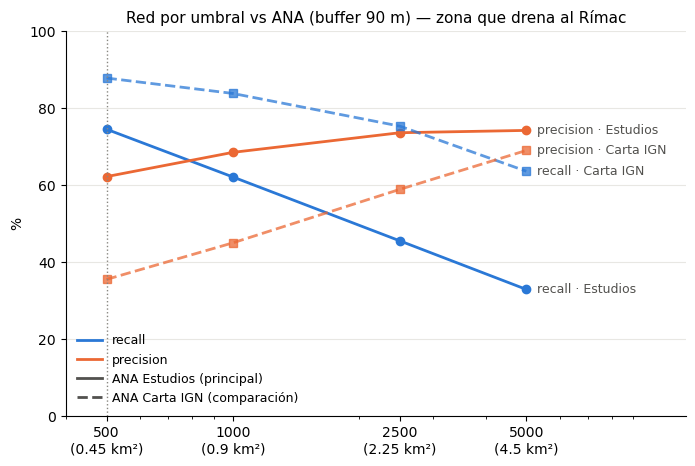

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
estilos = {"ANA Estudios": dict(ls="-", marker="o"), "ANA Carta IGN": dict(ls="--", marker="s", alpha=0.75)}
colores = {"recall_pct": "#2a78d6", "precision_pct": "#eb6834"}
for capa, gr in val.groupby("referencia", sort=False):
    for met, col in colores.items():
        ax.plot(gr.umbral_celdas, gr[met], color=col, lw=2, ms=6, **estilos[capa])
        ax.annotate(f"{met.split('_')[0]} · {capa.replace('ANA ', '')}", (gr.umbral_celdas.iloc[-1], gr[met].iloc[-1]),
                    xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color="#52514e")
ax.axvline(UMBRAL_RECOMENDADO, color="#898781", lw=1, ls=":")
ax.set_xscale("log"); ax.set_xticks(UMBRALES); ax.set_xticklabels([f"{u}\n({u*CELDA_M2/1e6:g} km²)" for u in UMBRALES])
ax.set_xlim(400, 12000); ax.set_ylim(0, 100); ax.set_ylabel("%"); ax.grid(axis="y", color="#e8e7e3")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"Red por umbral vs ANA (buffer {BUFFER_M} m) — zona que drena al Rímac", fontsize=11)
ax.legend(handles=[Line2D([], [], color="#2a78d6", lw=2, label="recall"), Line2D([], [], color="#eb6834", lw=2, label="precision"),
                   Line2D([], [], color="#52514e", lw=2, ls="-", label="ANA Estudios (principal)"),
                   Line2D([], [], color="#52514e", lw=2, ls="--", label="ANA Carta IGN (comparación)")], loc="lower left", fontsize=9, frameon=False)
fig.savefig(TERRENO / "validacion_red_ana.png", dpi=150, bbox_inches="tight")
plt.show()

## Paso 13 — Cruce con las cuencas candidatas
Para cada quebrada de referencia con coordenadas:
1. Si una cuenca candidata contiene al menos el 30 % de la línea de ANA, se asigna la que más contiene: `origen = "candidata"`.
   - Con umbral 500 la regla de "primera cuenca en la que entra la línea" fallaba: la línea cruza primero cuencas pequeñas del cono.
   - `consulta_m` = a qué distancia de la salida entra la línea en esa cuenca. `cuenca_en_salida` = la cuenca que contiene el extremo mismo (la regla literal).
2. Si no, ajusto el punto de salida (*snap*) al cauce más cercano con acumulación ≥ 100 celdas, como máximo a 150 m y sin contar el cauce principal. Luego delimito su cuenca con `watershed` desde ese punto: `origen = "referencia"`.

Chequeos:
- % de la línea de ANA que cae dentro de la cuenca;
- largo de la línea de ANA vs largo de nuestro cauce: desde el *pour point* hacia arriba, siguiendo la mayor acumulación mientras sea ≥ `UMBRAL_CAUCE`;
- área vs `area_ref_km2`.

In [11]:
snap_mask = (acc >= SNAP_UMBRAL) & valido & ~principal
sr, sc = np.where(snap_mask)
arbol_snap = cKDTree(np.array(rasterio.transform.xy(T, sr, sc)).T)

def cauce_arriba(r, c):
    # Largo (km) del cauce principal de la cuenca: desde (r, c) hacia arriba por la mayor acumulación, mientras acc >= UMBRAL_CAUCE.
    largo = 0.0
    while True:
        mejor = None
        for dr in (-1, 0, 1):
            for dc in (-1, 0, 1):
                r2, c2 = r + dr, c + dc
                if (dr or dc) and 0 <= r2 < R and 0 <= c2 < C and abajo[idx[r2, c2]] == idx[r, c] and acc[r2, c2] >= UMBRAL_CAUCE:
                    if mejor is None or acc[r2, c2] > acc[mejor]: mejor = (r2, c2)
        if mejor is None: return largo / 1000
        largo += paso_m[mejor]; r, c = mejor

tmp = Path(tempfile.mkdtemp())
perfil_i32 = perfil.copy(); perfil_i32.update(dtype="int32", nodata=0, compress="lzw")
def watershed_desde(r, c):
    pour = np.zeros((R, C), np.int32); pour[r, c] = 1
    with rasterio.open(tmp / "pp.tif", "w", **perfil_i32) as dst: dst.write(pour, 1)
    assert wbt.watershed(str(FDIR), str(tmp / "pp.tif"), str(tmp / "ws.tif")) == 0
    with rasterio.open(tmp / "ws.tif") as src: m = src.read(1) == 1
    return m & valido

def poligono(m):
    return shapely.make_valid(unary_union([shape(g) for g, v in features.shapes(m.astype(np.uint8), mask=m, transform=T, connectivity=4)]))

filas, poligonos_ref = [], {}
n_ref = 0
for _, f in ref[ref.salida_lat.notna()].iterrows():
    if f.nombre in asignada_cuadro:
        cid, a = asignada_cuadro[f.nombre], np.nan
    else:
        cid, a, p = cuenca_consulta(f.nombre)
    rs, cs = rasterio.transform.rowcol(T, f.x, f.y); cid_salida = int(ws[min(rs, R - 1), min(cs, C - 1)])
    fila = {"nombre": f.nombre, "en_catalogo": f.en_catalogo, "en_piloto": f.en_piloto, "fuente": f.fuente, "cuenca_ana": f.cuenca_ana, "cuenca_en_salida": cid_salida or "",
            "dist_salida_principal_m": f.dist_salida_principal_m, "consulta_m": a, "snap_m": np.nan}
    if cid:
        q = pp[pp.cuenca_id == cid].iloc[0]
        fila.update(origen="candidata", cuenca_id=str(cid), area_km2=q.area_km2, toca_borde=bool(q.toca_borde))
        poly, r0, c0 = cand.loc[cid, "geometry"], int(q.fila), int(q.col)
    else:
        d, j = arbol_snap.query([f.x, f.y])
        if d > SNAP_MAX_M:
            fila.update(origen="sin_cauce_cercano", cuenca_id="", area_km2=np.nan, toca_borde=np.nan, snap_m=round(d))
            filas.append(fila); continue
        n_ref += 1; r0, c0 = int(sr[j]), int(sc[j])
        m = watershed_desde(r0, c0)
        assert m.sum() == acc[r0, c0], "área ≠ acumulación"
        poly = poligono(m); cid_r = f"R{n_ref:02d}"; poligonos_ref[cid_r] = (f.nombre, poly, m, r0, c0)
        fila.update(origen="referencia", cuenca_id=cid_r, area_km2=round(m.sum() * CELDA_M2 / 1e6, 3), toca_borde=bool((m & borde).any()), snap_m=round(d))
    linea = geom_ref.get(f.nombre)           # las ubicadas por el Cuadro 04 no tienen línea de ANA
    fila["pct_linea_en_cuenca"] = round(100 * linea.intersection(poly).length / linea.length, 1) if linea is not None else np.nan
    fila["largo_ana_km"] = round(linea.length / 1000, 2) if linea is not None else np.nan
    fila["largo_cauce_nuestro_km"] = round(cauce_arriba(r0, c0), 2)
    filas.append(fila)
cruce = pd.DataFrame(filas).merge(ref[["nombre", "area_ref_km2", "largo_ref_km", "regla_salida"]], on="nombre")
cruce["dif_area_pct"] = (100 * (cruce.area_km2 - cruce.area_ref_km2) / cruce.area_ref_km2).round(1)
cruce["dif_largo_pct"] = (100 * (cruce.largo_cauce_nuestro_km - cruce.largo_ana_km) / cruce.largo_ana_km).round(1)
cruce["dif_largo_ref_pct"] = (100 * (cruce.largo_cauce_nuestro_km - cruce.largo_ref_km) / cruce.largo_ref_km).round(1)
cruce["n_refs_misma_cuenca"] = cruce.groupby("cuenca_id")["nombre"].transform("count").where(cruce.cuenca_id != "")
alertas = []
for _, f in cruce.iterrows():
    a = []
    if f.pct_linea_en_cuenca < 70: a.append("línea<70%")
    if abs(f.dif_area_pct) > 30: a.append("área>30%")
    if abs(f.dif_largo_pct) > 30: a.append("largo_ANA>30%")
    if abs(f.dif_largo_ref_pct) > 30: a.append("largo_ref>30%")
    if f.toca_borde is True: a.append("toca_borde")
    alertas.append(", ".join(a))
cruce["alertas"] = alertas
cruce.to_csv(TERRENO / "cruce_referencia.csv", index=False, encoding="utf-8-sig")

if poligonos_ref:
    g_ref = gpd.GeoDataFrame({"cuenca_id": list(poligonos_ref), "nombre": [v[0] for v in poligonos_ref.values()]},
                             geometry=[v[1] for v in poligonos_ref.values()], crs=CRS)
    g_ref = g_ref.merge(cruce[["cuenca_id", "area_km2", "toca_borde"]], on="cuenca_id")
    g_ref.to_crs("EPSG:4326").to_file(TERRENO / "cuencas_referencia.geojson", driver="GeoJSON")
print("Origen:", cruce.origen.value_counts().to_dict())
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 250)
display(cruce[cruce.en_catalogo][["nombre", "fuente", "origen", "cuenca_id", "area_km2", "area_ref_km2", "dif_area_pct", "pct_linea_en_cuenca",
                                  "largo_ana_km", "largo_cauce_nuestro_km", "largo_ref_km", "dif_largo_pct", "dif_largo_ref_pct", "alertas"]])

Origen: {'referencia': 35, 'candidata': 34, 'sin_cauce_cercano': 4}


,nombre,fuente,origen,cuenca_id,area_km2,area_ref_km2,dif_area_pct,pct_linea_en_cuenca,largo_ana_km,largo_cauce_nuestro_km,largo_ref_km,dif_largo_pct,dif_largo_ref_pct,alertas
0,Carossio,"SIGRID 123, Cuadro 04",candidata,41,0.528,0.4,32.0,NaN,NaN,0.37,1.3,NaN,-71.5,"área>30%, largo_ref>30%"
1,Corrales,"SIGRID 123, Cuadro 04",candidata,42,1.259,1.4,-10.1,NaN,NaN,1.36,2.4,NaN,-43.3,largo_ref>30%
2,Pedregal,"SIGRID 123, Cuadro 04",candidata,37,9.982,10.6,-5.8,NaN,NaN,5.30,6.1,NaN,-13.1,
3,Quebrada California,ANA Carta IGN,candidata,29,8.430,NaN,NaN,100.0,4.59,4.98,NaN,8.5,NaN,
4,Quebrada La Cantuta,ANA Carta IGN,candidata,33,13.888,15.0,-7.4,100.0,4.48,6.84,6.7,52.7,2.1,largo_ANA>30%
5,Quebrada La Ronda,ANA Carta IGN,candidata,40,8.818,9.0,-2.0,100.0,3.63,6.37,5.6,75.5,13.8,largo_ANA>30%
6,Quebrada Quirio,ANA Estudios,candidata,34,9.824,10.4,-5.5,100.0,2.00,5.16,5.6,158.0,-7.9,largo_ANA>30%
7,Quebrada Santa María,ANA Carta IGN,candidata,30,4.200,4.6,-8.7,72.5,3.35,3.06,5.0,-8.7,-38.8,largo_ref>30%
8,Quebrada Huaycoloro,ANA Carta IGN,referencia,R01,78.236,NaN,NaN,95.6,9.04,17.41,NaN,92.6,NaN,"largo_ANA>30%, toca_borde"
9,Quebrada Río Seco,ANA Carta IGN,referencia,R02,160.528,NaN,NaN,100.0,0.76,31.39,NaN,4030.3,NaN,"largo_ANA>30%, toca_borde"


### Cuencas de las quebradas que completes en `pendientes_ubicar.csv`
Uso la misma regla de *snap*: cauce con acumulación ≥ 100 celdas a ≤ 150 m del punto (sin contar el cauce principal) y `watershed` desde ahí. Les asigno `origen = "pendiente_manual"` e ids `P01`, `P02`…
También anoto qué cuenca candidata contiene el punto ajustado: si es su *pour point*, la cuenca es la misma.

In [12]:
pend_ok = pd.read_csv(RUTA_PEND).dropna(subset=["salida_lat", "salida_lon"]).reset_index(drop=True)
filas, poligonos_pend = [], {}
if len(pend_ok):
    xs_p, ys_p = warp_transform("EPSG:4326", CRS, pend_ok.salida_lon.tolist(), pend_ok.salida_lat.tolist())
    for k, f in pend_ok.iterrows():
        d, j = arbol_snap.query([xs_p[k], ys_p[k]])
        fila = {"nombre": f.nombre, "en_catalogo": True, "en_piloto": True, "fuente": "manual (pendientes_ubicar.csv)", "snap_m": round(d)}
        if d > SNAP_MAX_M:
            fila.update(origen="sin_cauce_cercano", cuenca_id="", alertas=f"sin cauce a ≤ {SNAP_MAX_M} m")
            filas.append(fila); continue
        r0, c0 = int(sr[j]), int(sc[j]); m = watershed_desde(r0, c0)
        cid_p = f"P{k + 1:02d}"; poligonos_pend[cid_p] = (f.nombre, poligono(m))
        cc_ = int(ws[r0, c0])                                    # candidata que contiene el punto ajustado
        frac_cand = m.sum() / (ws == cc_).sum() if cc_ else np.nan
        fila.update(origen="pendiente_manual", cuenca_id=cid_p, area_km2=round(m.sum() * CELDA_M2 / 1e6, 3), toca_borde=bool((m & borde).any()),
                    cuenca_en_salida=cc_ or "", igual_a_candidata=cc_ if cc_ and frac_cand >= 0.95 else "",
                    largo_cauce_nuestro_km=round(cauce_arriba(r0, c0), 2),
                    alertas=", ".join(filter(None, ["toca_borde" if (m & borde).any() else "",
                                                    f"sub-cuenca de la candidata {cc_} ({100 * frac_cand:.0f} %)" if cc_ and frac_cand < 0.95 else ""])))
        filas.append(fila)
    cruce = pd.concat([cruce, pd.DataFrame(filas)], ignore_index=True)
    cruce.to_csv(TERRENO / "cruce_referencia.csv", index=False, encoding="utf-8-sig")
if poligonos_pend:
    gpd.GeoDataFrame({"cuenca_id": list(poligonos_pend), "nombre": [v[0] for v in poligonos_pend.values()]},
                     geometry=[v[1] for v in poligonos_pend.values()], crs=CRS).to_crs("EPSG:4326").to_file(TERRENO / "cuencas_pendientes.geojson", driver="GeoJSON")
print(f"pendientes_ubicar.csv: {len(pend_ok)} con coordenadas | cuencas delimitadas: {len(poligonos_pend)}")
if filas: display(pd.DataFrame(filas))

pendientes_ubicar.csv: 0 con coordenadas | cuencas delimitadas: 0


## Figura: cuencas con nombre

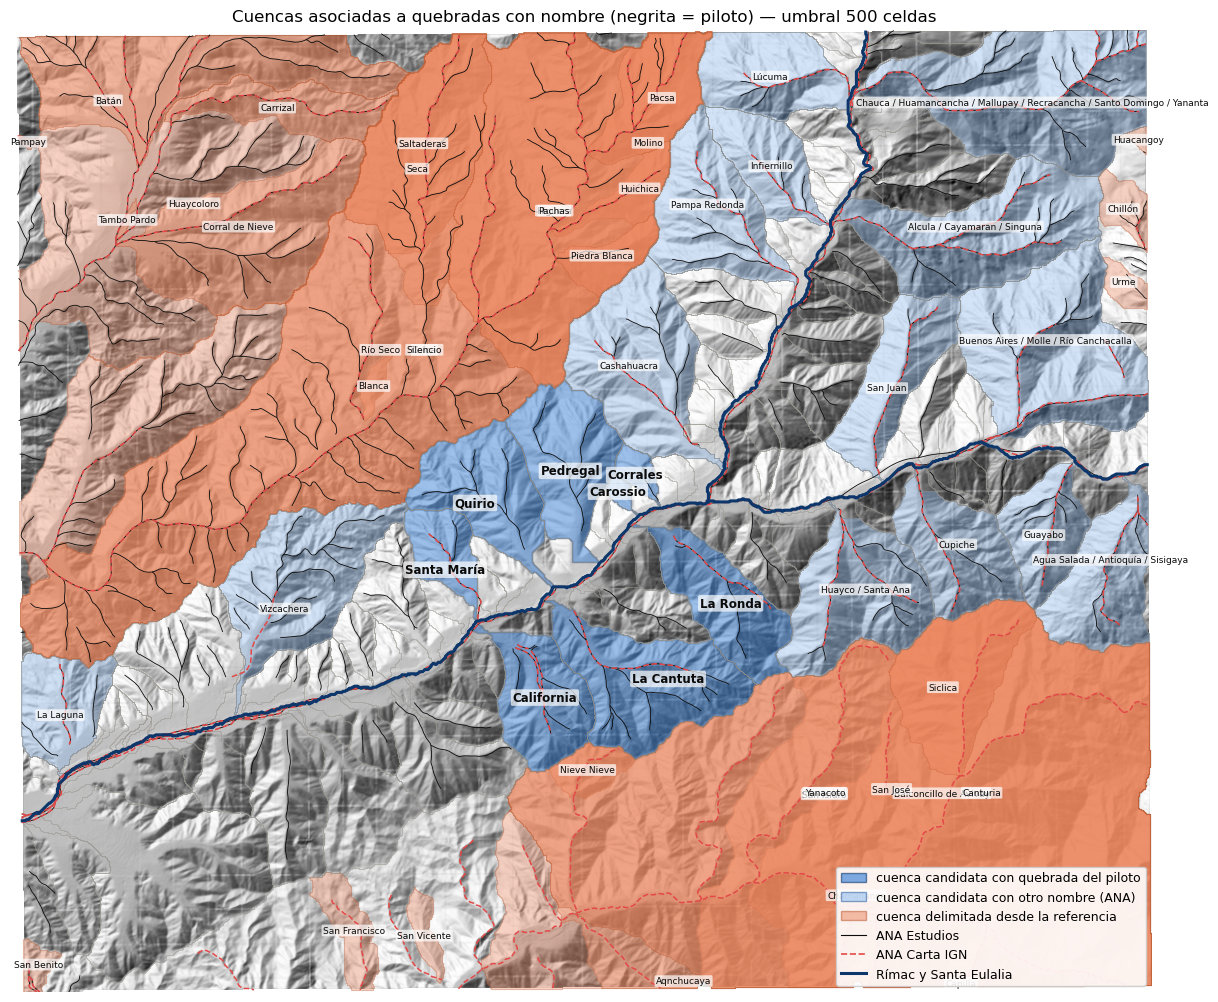

In [13]:
fig, ax = plt.subplots(figsize=(15, 12.5))
ext = (X0, X1, Y0, Y1)
ax.imshow(hs, cmap="gray", vmin=-0.2, vmax=1.0, extent=ext)
cand.boundary.plot(ax=ax, color="#9a9890", lw=0.4)
asoc = cruce[cruce.origen == "candidata"]
ids_cat = set(asoc.loc[asoc.en_piloto, "cuenca_id"].astype(int))
ids_otr = set(asoc.cuenca_id.astype(int)) - ids_cat
cand.loc[sorted(ids_otr)].plot(ax=ax, color="#86b6ef", alpha=0.35, edgecolor="#184f95", lw=0.6)
cand.loc[sorted(ids_cat)].plot(ax=ax, color="#2a78d6", alpha=0.45, edgecolor="#0d366b", lw=1.0)
if poligonos_ref:
    g_ref.plot(ax=ax, color="#ec835a", alpha=0.35, edgecolor="#b4532a", lw=0.8)
for k, gl in ana.items():
    gl.clip(zona_valida).plot(ax=ax, color="#0b0b0b" if k == "ANA Estudios" else "#e34948", lw=0.6 if k == "ANA Estudios" else 1.1,
                              linestyle="-" if k == "ANA Estudios" else "--")
for k, v in xy_rio.items():
    ax.plot(v[:, 0], v[:, 1], color="#0d366b", lw=2.2)
# Etiquetas: nombres por cuenca (sin "Quebrada")
if poligonos_pend:
    g_pend = gpd.GeoDataFrame({"cuenca_id": list(poligonos_pend)}, geometry=[v[1] for v in poligonos_pend.values()], crs=CRS)
    g_pend.plot(ax=ax, color="#1baf7a", alpha=0.4, edgecolor="#0b6b49", lw=1.0)
etiquetas = cruce[cruce.cuenca_id.fillna("") != ""].assign(n=lambda d: d.nombre.str.replace("Quebrada ", "", regex=False))
for cid, g in etiquetas.groupby("cuenca_id"):
    if cid.startswith("R"): poly = g_ref.set_index("cuenca_id").loc[cid, "geometry"]
    elif cid.startswith("P"): poly = g_pend.set_index("cuenca_id").loc[cid, "geometry"]
    else: poly = cand.loc[int(cid), "geometry"]
    pt = poly.representative_point()
    txt = " / ".join(g.n); en_cat = g.en_piloto.any()
    ax.text(pt.x, pt.y, txt, fontsize=8.5 if en_cat else 6.5, fontweight="bold" if en_cat else "normal", ha="center", va="center",
            color="#0b0b0b", bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.7))
ax.set_xlim(X0, X1); ax.set_ylim(Y0, Y1); ax.set_axis_off()
ax.legend(handles=[Patch(fc="#2a78d6", alpha=0.6, ec="#0d366b", label="cuenca candidata con quebrada del piloto"),
                   Patch(fc="#86b6ef", alpha=0.5, ec="#184f95", label="cuenca candidata con otro nombre (ANA)"),
                   Patch(fc="#ec835a", alpha=0.5, ec="#b4532a", label="cuenca delimitada desde la referencia"),
                   Line2D([], [], color="#0b0b0b", lw=0.8, label="ANA Estudios"),
                   Line2D([], [], color="#e34948", lw=1.2, ls="--", label="ANA Carta IGN"),
                   Line2D([], [], color="#0d366b", lw=2.2, label="Rímac y Santa Eulalia")], loc="lower right", fontsize=9, framealpha=0.9)
ax.set_title(f"Cuencas asociadas a quebradas con nombre (negrita = piloto) — umbral {UMBRAL_CAUCE} celdas", fontsize=12)
fig.savefig(TERRENO / "cuencas_con_nombres.png", dpi=160, bbox_inches="tight")
plt.show()

## Resumen fase 3

In [14]:
print(val.pivot(index="umbral_celdas", columns="referencia", values=["recall_pct", "precision_pct", "f1_pct"]).to_string())
print("\nUmbral recomendado (mayor F1 vs ANA Estudios):", UMBRAL_RECOMENDADO)
con = cruce[cruce.origen.isin(["candidata", "referencia"])]
print(f"\nQuebradas de referencia con coordenadas: {len(cruce)} | asociadas: {len(con)} "
      f"(candidata {int((con.origen == 'candidata').sum())}, referencia {int((con.origen == 'referencia').sum())})")
print("Sin cuenca:", cruce.loc[~cruce.origen.isin(["candidata", "referencia"]), "nombre"].tolist())
print("Del piloto sin coordenadas (pendientes_ubicar.csv):", len(pend))
print("\nPiloto con cuenca:")
print(cruce.loc[cruce.en_piloto == True, ["nombre", "fuente", "origen", "cuenca_id", "area_km2", "area_ref_km2", "dif_area_pct", "pct_linea_en_cuenca",
                                          "largo_cauce_nuestro_km", "largo_ref_km", "dif_largo_ref_pct", "alertas"]].to_string(index=False))
print("\nCon alertas (resto):", int(((~cruce.en_catalogo) & (cruce.alertas != "")).sum()), "de", int((~cruce.en_catalogo).sum()))

                 recall_pct              precision_pct                     f1_pct             
referencia    ANA Carta IGN ANA Estudios ANA Carta IGN ANA Estudios ANA Carta IGN ANA Estudios
umbral_celdas                                                                                 
500                    87.8         74.5          35.5         62.2          50.6         67.8
1000                   83.8         62.1          45.0         68.5          58.5         65.1
2500                   75.3         45.5          58.9         73.6          66.1         56.2
5000                   63.6         32.9          69.0         74.2          66.2         45.6

Umbral recomendado (mayor F1 vs ANA Estudios): 500

Quebradas de referencia con coordenadas: 73 | asociadas: 69 (candidata 34, referencia 35)
Sin cuenca: ['Quebrada Antivales', 'Quebrada Huarahuara', 'Quebrada Huarangal', 'Quebrada Pampa de Lara']
Del piloto sin coordenadas (pendientes_ubicar.csv): 16

Piloto con cuenca:
           